# 03 · Train/test split

This notebook splits the problems into **dev** (80%, to train and tune the model with
cross-validation) and **test** (20%, used once, at the end). The test score is only
worth something if the test set looks like the data the model will meet, and if no
test problem was seen in training.

**In short**
- **Near-duplicate groups stay whole**, so no near copy of a test problem is trained on.
- **The problems with no focus tag are kept**, in their own stratum. They are 46% of
  the data, the model must learn to predict no focus tag, and they carry the same other
  tags (`greedy`, `dp`) as the problems with one.
- **Each stratum is split by iterative stratification** (Sechidis et al., 2011 [1]).
  The focus stratum is balanced on the 8 focus tags, their 9 frequent pairs (such as
  `graphs & trees`) and the release year, the no-focus stratum on the year.
- **Fold 0 of 5 is the test set.** The same rule splits dev into 5 cross-validation
  folds.
- **Against random splits, 50 seeds each:**
  - it never leaks a duplicate pair across dev and test (random by problem: 17 to 34);
  - a typical focus tag is 1.5% off its overall share in test, against about 10% at
    random;
  - the worst tag is at most 8.1% off, against up to 52% at random;
  - a typical pair of focus tags is 4.3% off, against about 22% at random;
  - the share of problems with no focus tag and the release years match the dataset's
    7 to 8 times more closely.

The method (source: `figures/split_method.mmd`):

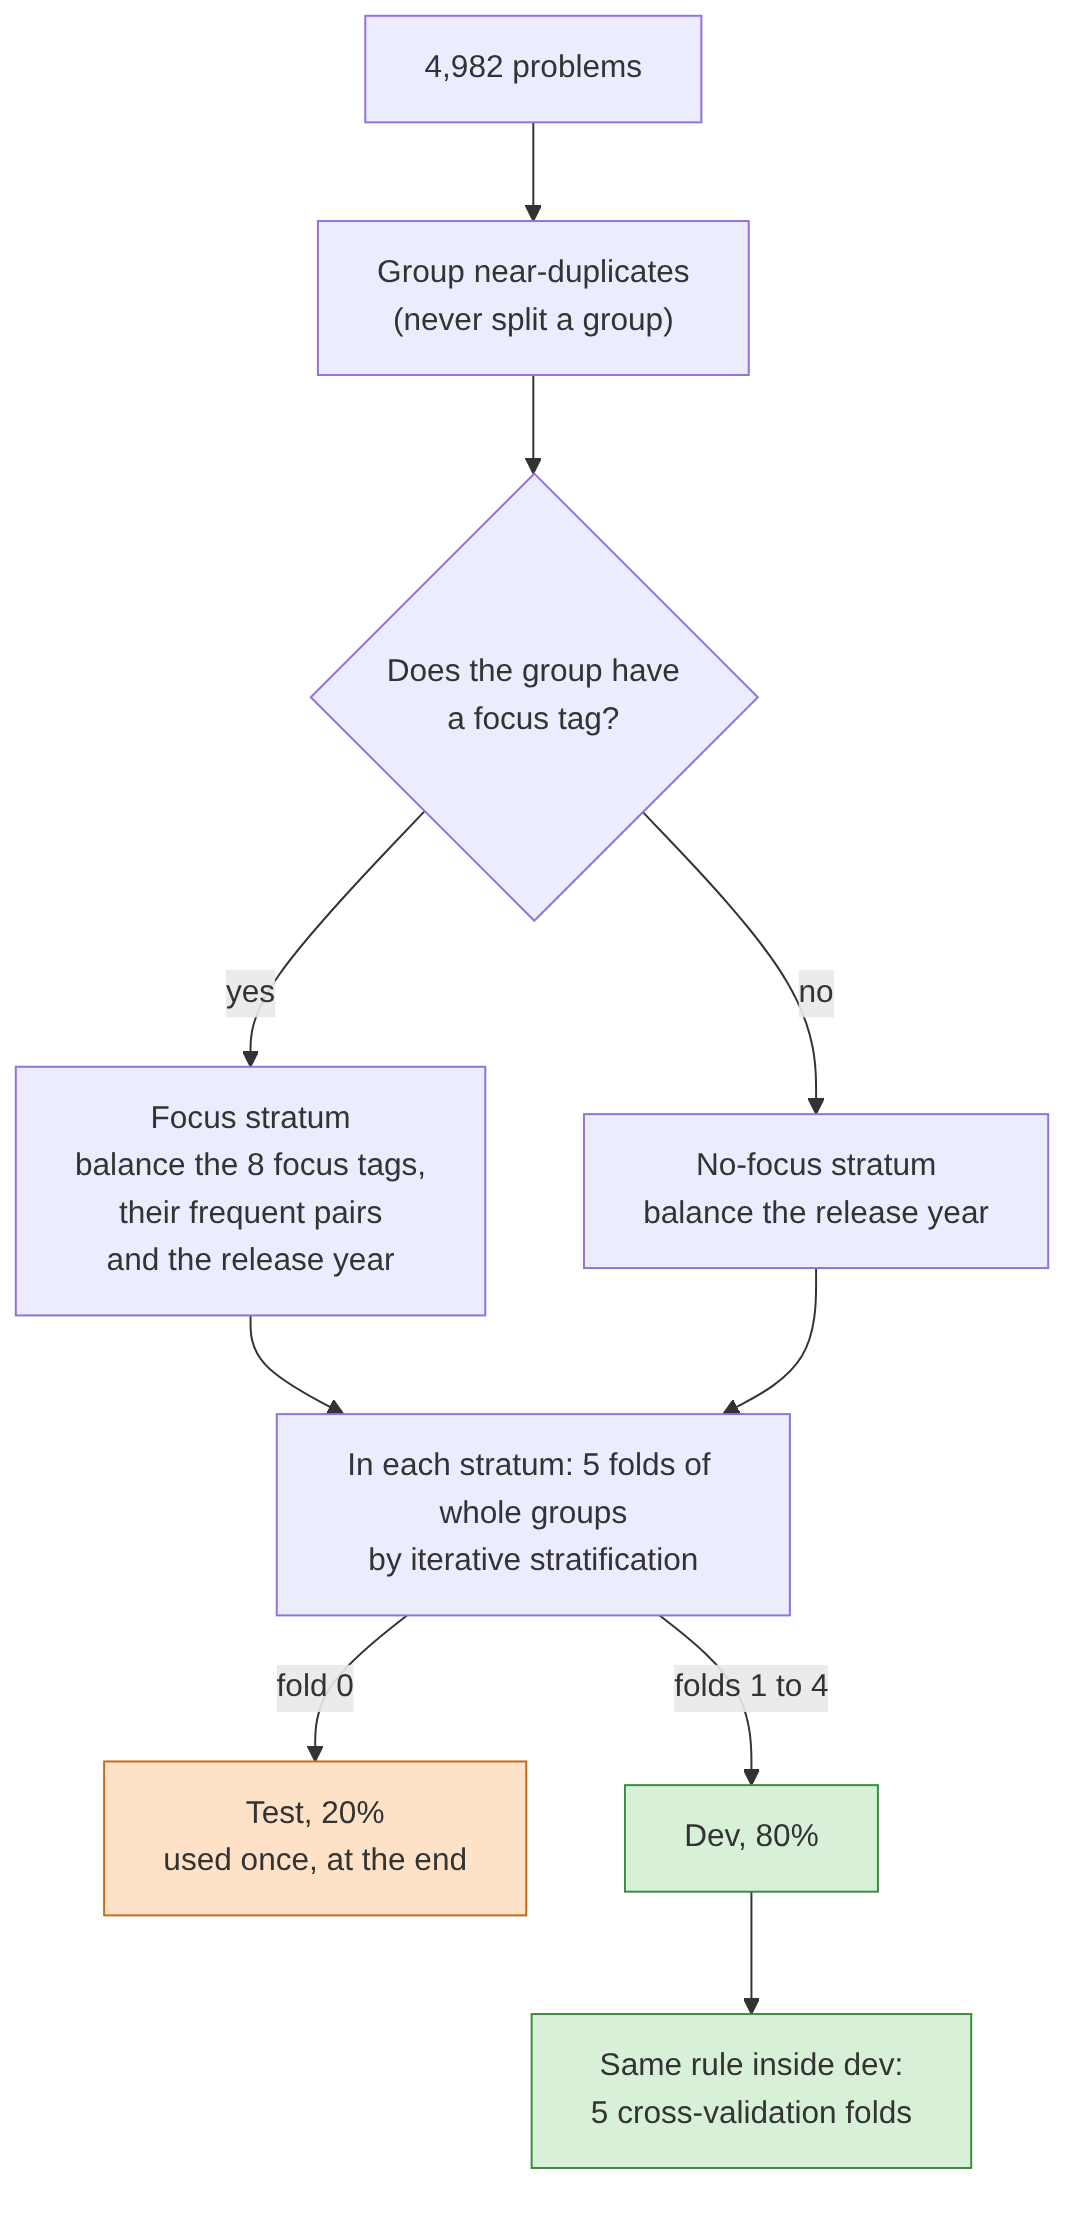

In [1]:
from IPython.display import Image

Image(filename="figures/split_method.png", width=460)

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from codeforces_tags.analysis.plotting import setup_style
from codeforces_tags.analysis.split_quality import (
    MEASURE_LABELS,
    SPLIT_METHODS,
    compare_split_methods,
    split_quality,
)
from codeforces_tags.config import (
    FOCUS_COLOR,
    FOCUS_TAGS,
    SPLIT_COMPARISON_SEEDS,
    SPLIT_FOLDS,
    SPLIT_MIN_PAIR_PROBLEMS,
    SPLIT_SEED,
)
from codeforces_tags.data.labels import frequent_pairs, multi_hot
from codeforces_tags.data.loading import load_dataset
from codeforces_tags.near_duplicates.detection import near_duplicate_groups
from codeforces_tags.splitting import freeze_split, make_split, release_years

setup_style()

df = load_dataset()
groups = near_duplicate_groups(df)
focus = multi_hot(df["tags"], FOCUS_TAGS)
pairs = frequent_pairs(focus, SPLIT_MIN_PAIR_PROBLEMS)
no_focus = ~focus.astype(bool).any(axis=1)
years = release_years(df)
print(f"{len(df):,} problems in {groups.nunique():,} near-duplicate groups")

4,982 problems in 4,900 near-duplicate groups


## 1. What the split must guarantee, and how it is measured

Each guarantee has one measure. The arrow says which way is better: **↓ lower**,
**↑ higher**.

| Measure | Better | Question it answers | Computed as |
|---|---|---|---|
| **leaked duplicate pairs** | ↓, must be 0 | Is a test problem a near copy of a training problem? | near-duplicate pairs with one problem in dev and the other in test |
| **max tag share deviation (%)** | ↓ | Is *every* focus tag as frequent in test as in all problems? | the share deviation (below) of each focus tag; the largest of the 8 |
| **mean tag share deviation (%)** | ↓ | Is a *typical* focus tag as frequent in test as in all problems? | the same deviation, averaged over the 8 focus tags |
| **max tag-pair share deviation (%)** | ↓ | Does *every* frequent pair of focus tags appear together in test as often as in all problems? | the share deviation of each pair of focus tags shared by at least 20 problems (9 pairs, section 3); the largest |
| **mean tag-pair share deviation (%)** | ↓ | Does a *typical* pair? | the same deviation, averaged over those pairs |
| **min test problems per tag** | ↑, up to the expected count | Is every tag scored on enough test problems? | test problems of the focus tag with the fewest of them; above its expected count (about 18 for `probabilities`) the tag is over-represented, which the tag share deviations catch |
| **no-focus share deviation (%)** | ↓ | Does test have as many problems with no focus tag as all problems? | the share deviation of the problems with no focus tag |
| **year mix distance (%)** | ↓ | Does test come from the same years as all problems? | the total variation distance between the year shares (below) |
| **test share (%)** | ≈ 20 | Is test the size asked for? | the share of problems in test: a control, not a quality, so that methods are compared at the same size |

**Share deviation** is how far a share in test is from the share in all problems, in
percent of the latter:
$100 \times |p_{\text{test}} - p_{\text{all}}| \,/\, p_{\text{all}}$.
It is relative so that rare and frequent tags count alike. 8% means that
`probabilities`, 1.85% of all problems, is between 1.70% and 1.99% of test; for `math`
(28.3%), 8% is 26.0% to 30.5%.

**Year mix distance** is the total variation distance between the release years of
test and of all problems, in percent:
$50 \times \sum_{y} |q_{y}^{\text{test}} - q_{y}^{\text{all}}|$, where $q_y$ is the
share of year $y$. It is the smallest share of test problems whose year would have to
change for test to have the years of all problems: 0.6% is 6 of 994. It is 0 when
the year mixes are identical, 100 when they share no year.

**Why these measures.**
- **Leakage.** A pair split across dev and test puts a near copy of a test problem in
  training, which inflates the test score (notebook 02).
- **Tag shares.** Per-tag scores are the main result. A tag over- or
  under-represented in test biases its score.
- **Tag pairs.** Focus tags co-occur: 262 problems are both `math` and `number theory`,
  124 both `graphs` and `trees`. A test set that keeps each tag's share but not the
  pairs could hold `trees` problems with too few `graphs` among them, and score `trees`
  on another mix than the data.
- **Rare tags.** `probabilities` has 92 problems and `games` 105, so a 20% test set
  holds about 18 and 21 of them. A few more or fewer change their score.
- **No focus tag.** Every tag predicted on these problems is a false positive, so
  their share in test weighs on precision (section 2).
- **Years.** The tag mix and the share of problems with no focus tag drift over time
  (section 2).

These adapt the measures of Sechidis et al. [1]. Their *Labels Distribution* averages,
over labels and folds, the absolute gap between a label's ratio of positive to negative
examples in a fold and in the whole dataset. The tag share deviations compare shares
instead, relative to the overall share so that rare tags register, and also report the
worst tag. Their count of folds with no positive example of a label is the failure
that *min test problems per tag* guards against. Their *Examples Distribution* checks
the fold sizes, as *test share* does.

## 2. Why keep the problems with no focus tag

Dropping the problems with none of the 8 focus tags would make a smaller, cleaner task,
but a wrong one. They are almost half of the problems, and their share drifts over time,
like the tag mix:

In [3]:
period = np.where(years <= 2020, f"{years.min()}-2020", f"2021-{years.max()}")
pd.DataFrame(
    {
        "problems": no_focus.groupby(period).size(),
        "share with no focus tag": no_focus.groupby(period).mean().map("{:.1%}".format),
        "share of math": focus["math"].groupby(period).mean().map("{:.1%}".format),
    }
).T.assign(all=[len(df), f"{no_focus.mean():.1%}", f"{focus['math'].mean():.1%}"])

,2010-2020,2021-2022,all
problems,3720,1262,4982
share with no focus tag,49.2%,37.6%,46.2%
share of math,24.9%,38.3%,28.3%


They also share their other tags with the problems that have a focus tag. The most
frequent tags outside the 8, and how often each comes with a focus tag:

In [4]:
tags = df["tags"].explode().dropna()
other_tags = tags[~tags.isin(FOCUS_TAGS)]
has_focus = ~no_focus
has_other = pd.Series(df.index.isin(other_tags.index), index=df.index)
also_other = has_other[has_focus].mean()
print(f"{also_other:.0%} of the problems with a focus tag also have a tag outside the 8")
with_focus = has_focus.loc[other_tags.index].groupby(other_tags.to_numpy()).mean()
pd.DataFrame(
    {"problems": other_tags.value_counts(), "share with a focus tag": with_focus}
).sort_values("problems", ascending=False).head(6).style.format(
    {"share with a focus tag": "{:.0%}"}
)

89% of the problems with a focus tag also have a tag outside the 8


,problems,share with a focus tag
greedy,1740,47%
implementation,1595,39%
constructive algorithms,1036,56%
dp,984,51%
brute force,836,53%
data structures,782,44%


- **The model will meet them.** For almost half of the problems the labelled answer is
  "no focus tag", so the model must learn to predict nothing.
- **They keep precision honest.** They are negatives for all 8 tags at once. Without
  them, the test set would never ask the model to stay silent, so the false positives
  it makes on such problems would go unseen, and precision and F1 would look better
  than they are.
- **Tags co-occur.** A focus tag rarely comes alone: 89% of the problems with one also
  carry a tag outside the 8. Frequent ones such as `greedy` and `dp` sit in both
  halves: 47% of the `greedy` problems and 51% of the `dp` ones have a focus tag, close
  to the 54% of all problems. Keeping both halves shows the model `greedy` or `dp`
  problems with and without a focus tag, so it learns what signals the focus tag
  itself, not the kind of problem. Without the no-focus half, every `greedy` or `dp`
  problem in training would have a focus tag, against about half in the data.
- **One caveat.** 41 of them have no tag at all, and a few of those look like tree,
  graph or game problems (notebook 01). Their labels may be incomplete, so the model's
  false positives on them deserve a second look.

**Why a stratum of their own.** Iterative stratification balances labels, and a
problem with no focus tag has none to balance. Splitting these problems on their own,
balanced by year, puts nearly the same number of them in every fold. Their share then
stays close to the overall one even though it drifts from 49% to 38% over time. It
also leaves the stratifier free to balance the 8 tags and their pairs in the other
stratum.

## 3. The method, step by step

| Step | What | Why |
|---|---|---|
| 1. Group | Near-duplicate groups from `near_duplicate_groups(df)` (notebook 02) | A group goes to one side, so no pair leaks |
| 2. Two strata | A group is in the focus stratum when any member has a focus tag; otherwise in the no-focus stratum | Keeps each group whole, and keeps the no-focus share close to the overall one |
| 3. Stratify | Iterative stratification assigns whole groups to 5 folds. It balances the 8 focus tags, their 9 frequent pairs and the year in the focus stratum, the year in the other | A random split cannot keep 8 tag shares at once; iterative stratification places the rarest labels first |
| 4. Test | Fold 0 of each stratum is the test set: 20% | One frozen test set, used once at the end |
| 5. Dev folds | The same rule, applied inside dev, gives 5 cross-validation folds | Tuning gets the same kind of folds as the final test (measured below) |

### How iterative stratification works

Iterative stratification (Sechidis et al. [1], Algorithm 1) fills the folds one label
at a time. Each fold keeps two counters: how many items it still needs, and how many
items with each label. The rarest label goes first, and each of its items goes to the
fold that needs that label most. Here an item is a whole near-duplicate group, and its
labels are the focus tags, the frequent pairs of focus tags and the release year of its
members (one column per year).
The diagram (source: `figures/iterative_stratification.mmd`):

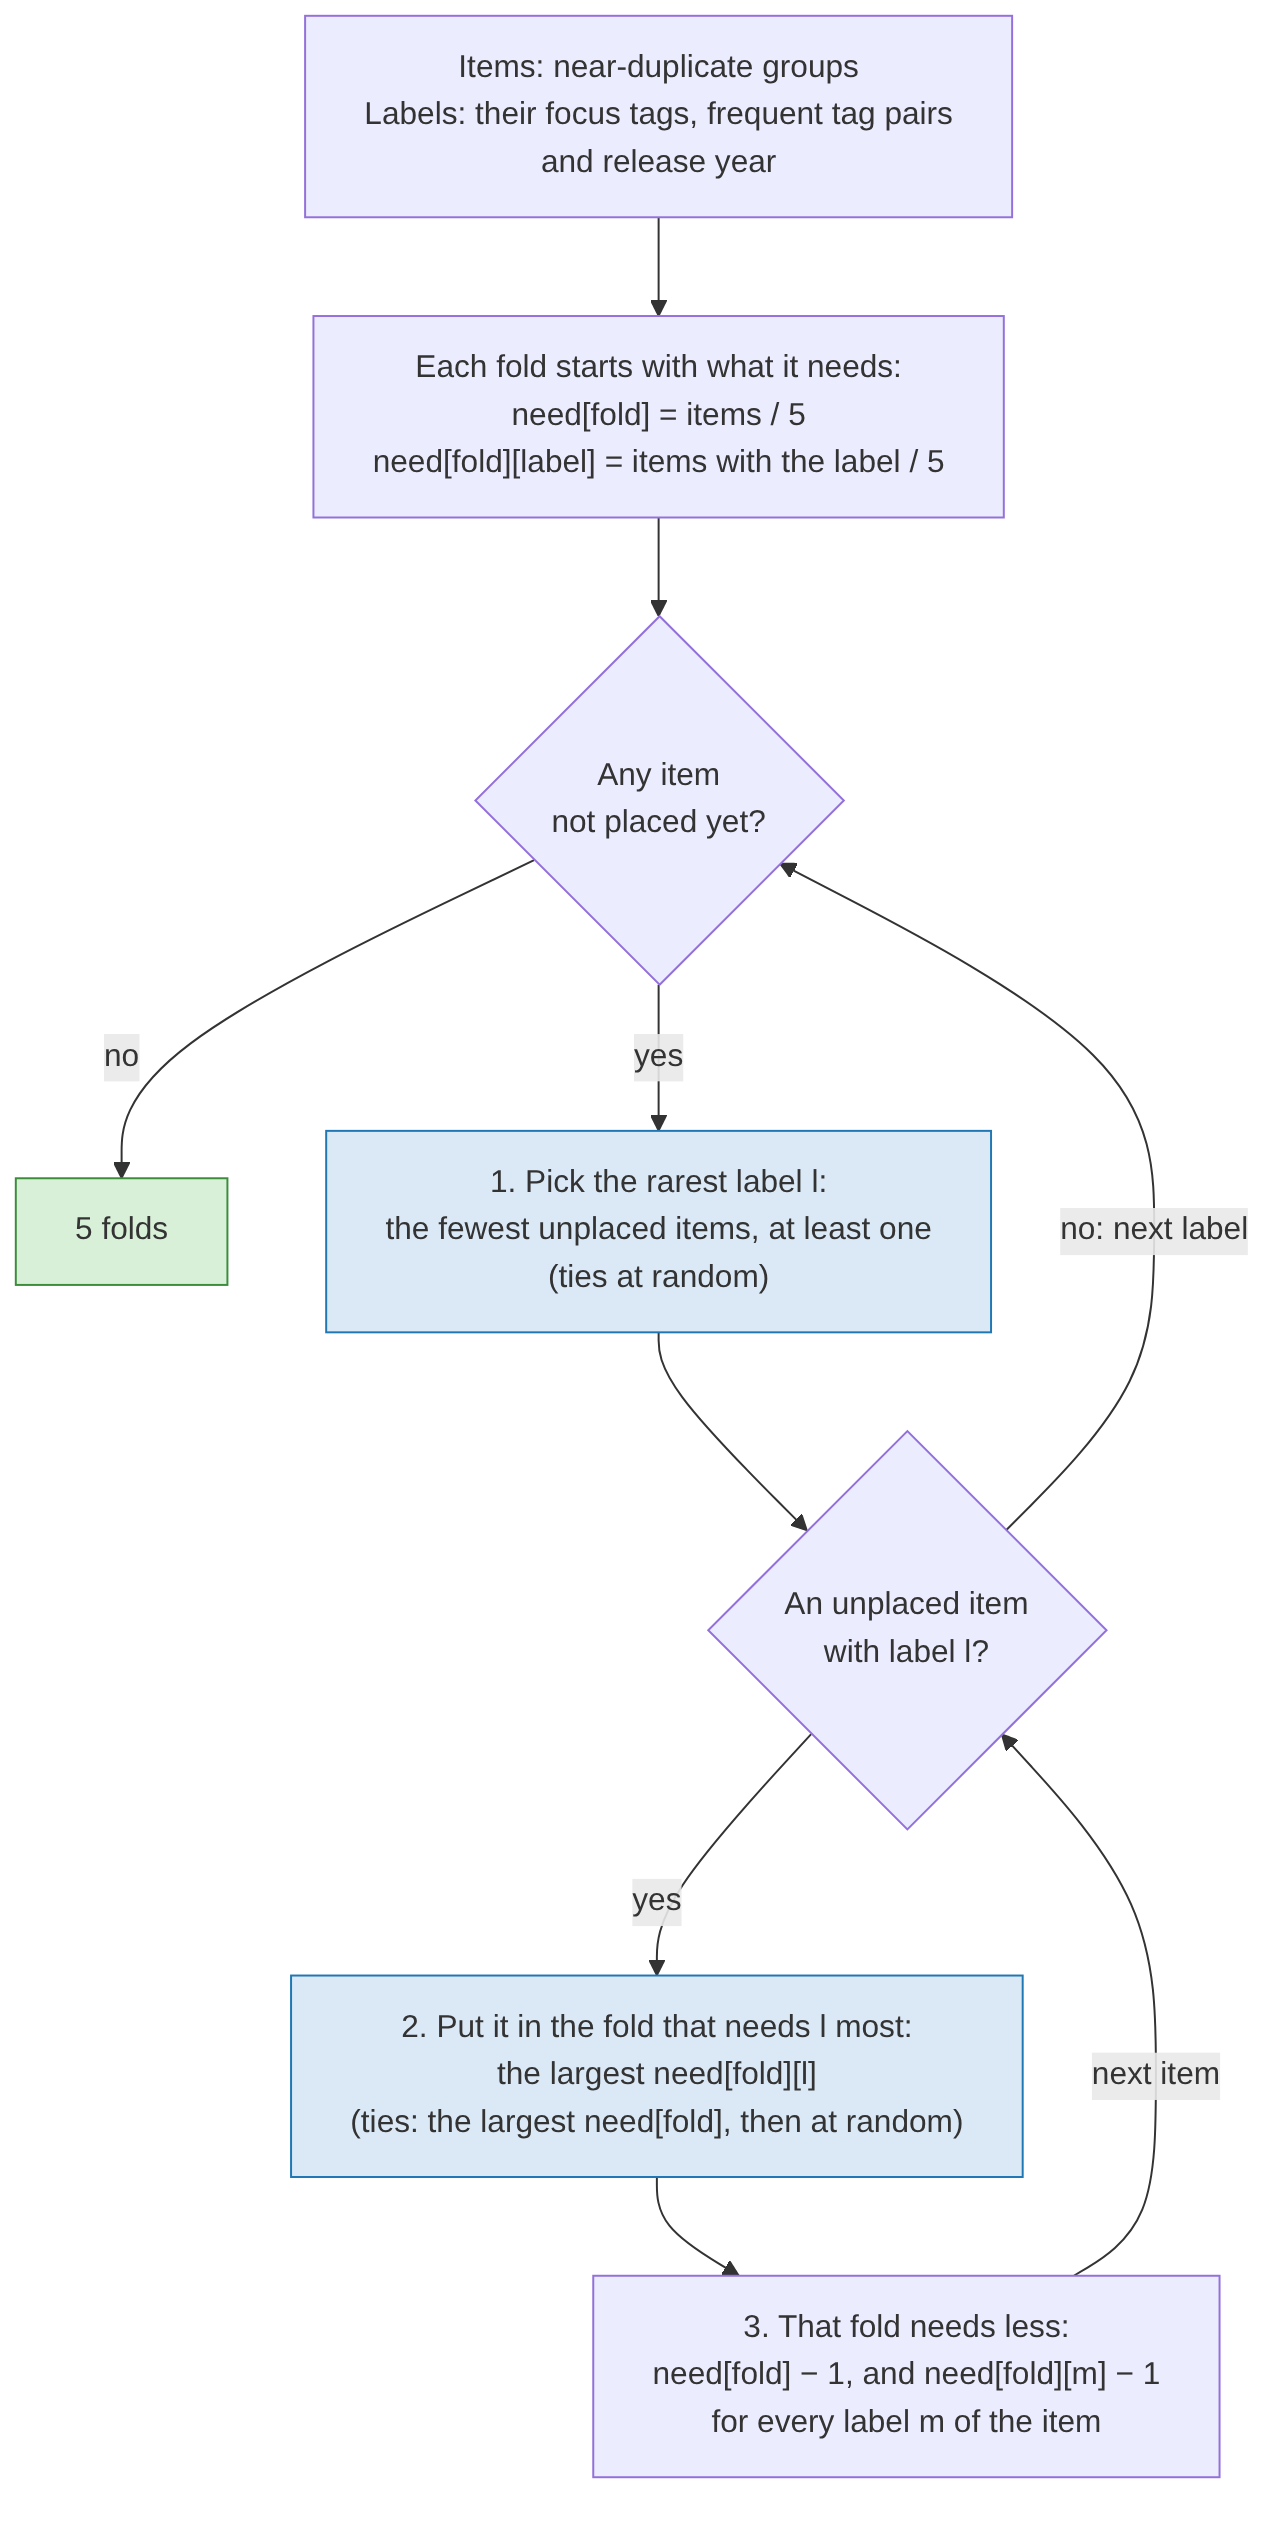

In [5]:
Image(filename="figures/iterative_stratification.png", width=520)

The same steps in pseudo code, with `k` = 5 folds:

```text
for each fold f:
    need[f] = number of items / k                  # items fold f still needs
    for each label l:
        need[f][l] = number of items with l / k    # items with l fold f still needs

while some item is not placed:
    l = the label with the fewest unplaced items, at least one
        # the rarest first; ties at random
    for each unplaced item x with label l:
        f = the fold with the largest need[f][l]   # the fold that needs l most
            # ties: the largest need[f], then at random
        place x in fold f
        need[f] = need[f] - 1
        for each label m of x:
            need[f][m] = need[f][m] - 1
```

- **Why the rarest label first.** A bad placement of a rare label cannot be repaired
  later. Frequent labels have enough items left to even out.
- **Why two counters.** `need[f][l]` balances each label across the folds. `need[f]`
  breaks the ties, so that the folds also keep about the same size.
- **In this data.** The rarest labels are tag pairs, so they are placed first:
  `graphs & number theory` (23 groups), then `math & games`, `math & trees`,
  `math & strings` and `math & probabilities`. The rarest tag, `probabilities`, comes
  next, then the other pairs, the oldest years and the rarer tags in turn; the frequent
  tags, such as `math`, come last. Every group has a year, so no item is left without a
  label (the paper places such items last, by `need[f]` alone).
- **The seed** (`SPLIT_SEED`) shuffles the order of the items and breaks the ties.
  Another seed gives another split of similar quality (section 4).
- **Pairs as labels.** The algorithm balances every label on its own, not how often two
  labels appear together (the paper's "relaxed" interpretation of stratification). So
  each pair of focus tags shared by at least 20 problems (`SPLIT_MIN_PAIR_PROBLEMS`,
  about 4 per fold) is a label too: a group with both `graphs` and `trees` also carries
  `graphs & trees`. That makes 9 pairs, from `math & number theory` (262 problems) to
  `graphs & number theory` (23). Rarer pairs have too few problems to balance, and
  the next one, `strings & trees`, has 15: any threshold from 16 to 23 picks the same
  9 pairs.

The package `iterative-stratification` [2] implements it as
`MultilabelStratifiedKFold`. The split used (seed `SPLIT_SEED` in `config.py`):

In [6]:
split = make_split(df, groups, seed=SPLIT_SEED)
is_test = split["part"] == "test"
sizes = split.assign(fold=split["fold"].where(~is_test, "test")).groupby("fold").size()
print(f"dev: {(~is_test).sum():,} problems, test: {is_test.sum():,} ({is_test.mean():.1%})")
print("problems per dev fold, and in test:", sizes.to_dict())
split_quality(df, groups, is_test).rename(MEASURE_LABELS).to_frame("test").round(1)

dev: 3,988 problems, test: 994 (20.0%)
problems per dev fold, and in test: {0: 806, 1: 790, 2: 797, 3: 795, 4: 800, 'test': 994}


,test
leaked duplicate pairs ↓,0.0
max tag share deviation (%) ↓,3.1
mean tag share deviation (%) ↓,1.2
max tag-pair share deviation (%) ↓,12.3
mean tag-pair share deviation (%) ↓,4.4
min test problems per tag ↑,18.0
no-focus share deviation (%) ↓,0.2
year mix distance (%) ↓,0.6
test share (%) ≈ 20,20.0


No duplicate pair leaks, and the worst focus tag is 3.1% off its overall share. The
worst pair, `math & strings`, is 12.3% off: 7 test problems where 8.0 are expected, and
with so few, one problem is 12.5%. Each focus tag, each frequent pair and the problems
with no focus tag have about the same share in dev and in test:

In [7]:
shares = pd.concat([focus, pairs, no_focus.astype(int).rename("no focus tag")], axis=1)
pd.DataFrame(
    {
        "all": shares.mean(),
        "dev": shares[~is_test].mean(),
        "test": shares[is_test].mean(),
        "test problems": shares[is_test].sum(),
    }
).style.format({"all": "{:.1%}", "dev": "{:.1%}", "test": "{:.1%}"})

,all,dev,test,test problems
math,28.3%,28.3%,28.3%,281
graphs,10.9%,10.9%,10.9%,108
strings,8.5%,8.5%,8.6%,85
number theory,7.0%,7.0%,7.2%,72
trees,6.5%,6.5%,6.3%,63
geometry,3.3%,3.3%,3.3%,33
games,2.1%,2.1%,2.1%,21
probabilities,1.8%,1.9%,1.8%,18
math & graphs,1.5%,1.5%,1.5%,15
math & strings,0.8%,0.8%,0.7%,7


**Inside dev.** The same measures, for each cross-validation fold against all of dev.
Here the fold plays the part of test: *min test problems per tag* counts the fold's
problems, and *test share* is the fold's share of dev.

In [8]:
dev = ~is_test
dev_folds = {
    f"fold {k}": split_quality(df[dev], groups[dev], split.loc[dev, "fold"] == k)
    for k in range(SPLIT_FOLDS)
}
pd.DataFrame(dev_folds).rename(MEASURE_LABELS).round(1)

,fold 0,fold 1,fold 2,fold 3,fold 4
leaked duplicate pairs ↓,0.0,0.0,0.0,0.0,0.0
max tag share deviation (%) ↓,5.8,3.8,7.2,2.0,5.7
mean tag share deviation (%) ↓,1.6,2.0,1.6,1.3,1.7
max tag-pair share deviation (%) ↓,13.9,12.2,8.8,9.1,9.4
mean tag-pair share deviation (%) ↓,4.7,5.5,4.1,4.2,4.8
min test problems per tag ↑,15.0,15.0,15.0,15.0,14.0
no-focus share deviation (%) ↓,0.5,0.1,0.1,0.1,0.5
year mix distance (%) ↓,0.5,1.0,0.8,0.5,0.8
test share (%) ≈ 20,20.2,19.8,20.0,19.9,20.1


No fold leaks a duplicate pair, and the deviations stay close to the test set's. The
largest come from the smallest labels, where one problem weighs most: `games` in fold 2
(18 problems where 16.8 are expected, 7.2%) and `math & games` in fold 0 (4 where 4.6
are expected, 13.9%). In dev, `graphs & number theory` has 18 problems, under the
threshold of 20, so the dev folds balance the other 8 pairs.

## 4. Compared with random splits

Three ways to draw a 20% test set. Each name says what is drawn, and how:

| Method | Draws | How | Close to | Guarantees |
|---|---|---|---|---|
| **random by problem** | problems, one by one | at random | `train_test_split` | nothing: near-duplicate pairs can be split, and tag shares depend on the seed |
| **random by group** | whole near-duplicate groups | at random | `GroupShuffleSplit` | no leaked pair; tag shares still depend on the seed |
| **stratified by group** | whole near-duplicate groups | iterative stratification, in two strata, with the frequent tag pairs as labels (section 3) | `MultilabelStratifiedKFold` on groups | no leaked pair, and tag, tag-pair, no-focus and year shares close to the overall ones |

Each method draws its test set with the same 50 seeds (`SPLIT_COMPARISON_SEEDS`), and
each test set is measured with the measures of section 1. Below, the mean over the
seeds and the range:

In [9]:
results = compare_split_methods(df, groups, seeds=range(SPLIT_COMPARISON_SEEDS))
labelled = results.rename(columns=MEASURE_LABELS)
summary = labelled.groupby(level="method", sort=False).agg(["mean", "min", "max"]).T
summary.round(1)

method                                    random by problem  random by group  \
leaked duplicate pairs ↓            mean               25.8              0.0   
                                    min                17.0              0.0   
                                    max                34.0              0.0   
max tag share deviation (%) ↓       mean               24.2             28.1   
                                    min                 4.8             10.1   
                                    max                42.8             52.1   
mean tag share deviation (%) ↓      mean                9.4             10.0   
                                    min                 2.4              5.4   
                                    max                17.6             17.5   
max tag-pair share deviation (%) ↓  mean               54.5             55.4   
                                    min                23.8             22.9   
                                    max                97.2             97.6   
mean tag-pair share deviation (%) ↓ mean               22.3             22.1   
                                    min                12.3             10.9   
                                    max                37.5             39.3   
min test problems per tag ↑         mean               17.1             17.3   
                                    min                11.0              9.0   
                                    max                23.0             24.0   
no-focus share deviation (%) ↓      mean                2.5              2.4   
                                    min                 0.0              0.1   
                                    max                 7.6              8.8   
year mix distance (%) ↓             mean                3.9              3.7   
                                    min                 1.7              1.9   
                                    max                 5.3              6.6   
test share (%) ≈ 20                 mean               20.0             20.0   
                                    min                20.0             19.9   
                                    max                20.0             20.2   

method                                    stratified by group  
leaked duplicate pairs ↓            mean                  0.0  
                                    min                   0.0  
                                    max                   0.0  
max tag share deviation (%) ↓       mean                  4.1  
                                    min                   1.6  
                                    max                   8.1  
mean tag share deviation (%) ↓      mean                  1.5  
                                    min                   0.5  
                                    max                   2.7  
max tag-pair share deviation (%) ↓  mean                 12.2  
                                    min                   8.1  
                                    max                  14.3  
mean tag-pair share deviation (%) ↓ mean                  4.3  
                                    min                   2.6  
                                    max                   6.5  
min test problems per tag ↑         mean                 18.4  
                                    min                  18.0  
                                    max                  20.0  
no-focus share deviation (%) ↓      mean                  0.3  
                                    min                   0.0  
                                    max                   0.9  
year mix distance (%) ↓             mean                  0.5  
                                    min                   0.3  
                                    max                   1.0  
test share (%) ≈ 20                 mean                 20.0  
                                    min                  19.8  
                               

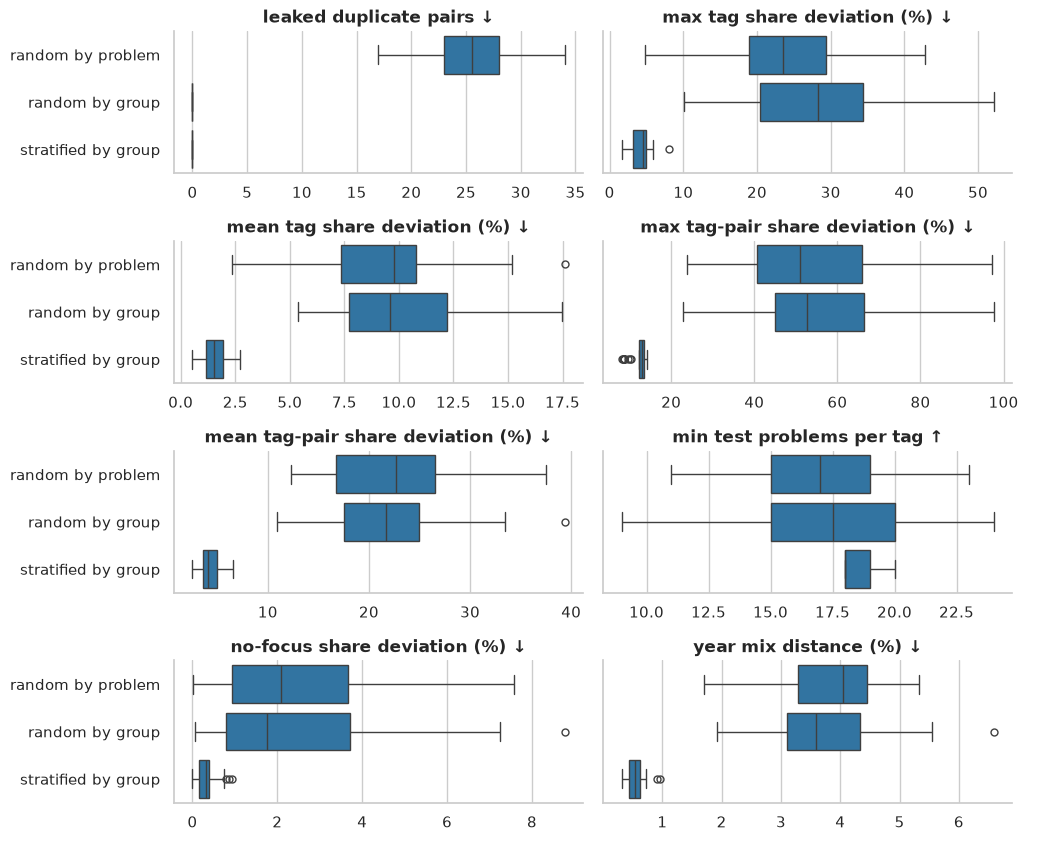

In [10]:
measures = labelled.drop(columns=MEASURE_LABELS["test share (%)"])
long = measures.reset_index().melt(id_vars=["method", "seed"], var_name="measure")
grid = sns.catplot(
    data=long,
    x="value",
    y="method",
    col="measure",
    kind="box",
    col_wrap=2,
    sharex=False,
    height=2.2,
    aspect=2.4,
    order=list(SPLIT_METHODS),
    color=FOCUS_COLOR,
)
grid.set_titles("{col_name}")
grid.set_axis_labels("", "")
plt.show()

**Reading the comparison** (↓ lower is better, ↑ higher is better).
- **Leakage ↓.** Random by problem leaks 17 to 34 of the 82 duplicate pairs, 26 on
  average. Both methods by group leak none.
- **Tag shares ↓.** Grouping alone does not balance the tags. With random by group, a
  typical tag is 10% off its overall share, and the worst 28% off on average, up to
  52%. Stratification brings these to 1.5% and 4.1%, and the worst never goes above
  8.1%.
- **Tag pairs ↓.** At random, a typical frequent pair of focus tags is about 22% off
  its overall share, and the worst about 55% off on average, up to 98%. Stratified by
  group, with the pairs as labels, brings these to 4.3% and 12.2%, at most 14.3%. A
  pair expects 5 to 52 test problems (a fifth of its 23 to 262), so one problem moves
  a small pair by 10% or more.
- **Rare tags ↑.** A 20% test set should hold about 18 `probabilities` problems.
  Stratified by group gives every tag at least 18 test problems for every seed; random
  by group leaves as few as 9 for some seeds. Random splits sometimes give more, up to
  24, but only by over-representing the rare tags: 24 is 30% above the 18.4 expected
  for `probabilities`.
- **No-focus share and years ↓.** Stratified by group keeps the no-focus share 0.3%
  off on average, against about 2.5% at random. Its year mix distance is 0.5%, against
  about 3.8%.
- **Test share ≈ 20.** All three put 19.8% to 20.2% of the problems in test, so the
  comparison is at equal size. Stratification trades a little precision on size for
  balance on labels, as Sechidis et al. [1] observed.

**What this does not show.** These measures describe the split, not a model's score.
Whether a balanced split also makes the score more stable is checked when the model is
trained.

## 5. The frozen split

The split is saved to `assets/split/split.csv`: one row per problem, with its part, its
dev fold and its near-duplicate group. Training and evaluation read it with
`load_split()`, so the test set never changes, and they take the groups from it rather
than grouping a subset again; `load_split()` fails if a group spans two parts or two
folds. Re-running this notebook checks the saved split rather than overwriting it, and
fails if the method now gives another split:

In [11]:
print(freeze_split(split))

split.csv matches the split (4,982 problems)


## 6. Conclusion

- **No leakage.** Near-duplicate groups never cross the split, nor the dev folds.
- **A representative test set.** In the split used:
  - every focus tag is within 3.1% of its overall share (1.2% on average), and the
    rarest, `probabilities`, has 18 test problems;
  - every frequent pair of focus tags is within 12.3% of its overall share (4.4% on
    average);
  - the share of problems with no focus tag is within 0.2% of the dataset's;
  - the year mix distance is 0.6%, against about 3.8% for a random split.
- **The problems with no focus tag stay**, in their own stratum. The model must learn
  to predict nothing for them, they keep precision honest, and they keep the tag
  co-occurrence real: they carry the same other tags (`greedy`, `dp`) as the problems
  with a focus tag, so the model learns what tells the two apart.
- **Cross-validation folds are built the same way**, with no pair leaked and
  deviations close to the test set's; the largest, `math & games` in fold 0 (13.9%), is 4
  problems where 4.6 are expected.
- **Next:** train the model on dev with the 5 folds, choose it on out-of-fold
  predictions, then score it once on test, with bootstrap confidence intervals over the
  near-duplicate groups.

## References

[1] Sechidis K., Tsoumakas G., Vlahavas I. (2011) On the Stratification of Multi-Label
Data. In: Gunopulos D., Hofmann T., Malerba D., Vazirgiannis M. (eds) Machine Learning
and Knowledge Discovery in Databases. ECML PKDD 2011. Lecture Notes in Computer Science,
vol 6913. Springer, Berlin, Heidelberg.
[doi:10.1007/978-3-642-23808-6_10](https://doi.org/10.1007/978-3-642-23808-6_10)

[2] Bradberry T. J. (2018) iterative-stratification: scikit-learn cross validators for
iterative stratification of multilabel data.
[github.com/trent-b/iterative-stratification](https://github.com/trent-b/iterative-stratification)